In [ ]:
!pip install opendatasets

In [ ]:
!pip install legacy-cgi

In [ ]:
import opendatasets as od
od.download("https://www.kaggle.com/datasets/shreyashbhimanwar/rotten-fruits?resource=download")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: sabrah 
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/shreyashbhimanwar/rotten-fruits


100%|██████████| 199M/199M [00:02<00:00, 100MB/s]


### 2.1 Dataset Class Inspection

In this step, we inspect the class labels in the
training and testing directories.

We verify that both directories contain the same
classes before constructing the final data pipeline.

In [ ]:
import os

# Define dataset paths
train_path = "/content/rotten-fruits/dataset/train"
test_path = "/content/rotten-fruits/dataset/test"

# Get class names
train_classes = sorted([
    folder for folder in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, folder))
])

test_classes = sorted([
    folder for folder in os.listdir(test_path)
    if os.path.isdir(os.path.join(test_path, folder))
])

# Display results
print("Training Classes:", len(train_classes))
print(train_classes)

print("\nTesting Classes:", len(test_classes))
print(test_classes)

# Compare classes
print("\nClasses missing from testing:")
print(sorted(set(train_classes) - set(test_classes)))

print("\nExtra classes in testing:")
print(sorted(set(test_classes) - set(train_classes)))

Training Classes: 12
['Apple_Bad', 'Apple_Good', 'Banana_Bad', 'Banana_Good', 'Guava_Bad', 'Guava_Good', 'Lime_Bad', 'Lime_Good', 'Orange_Bad', 'Orange_Good', 'Pomegranate_Bad', 'Pomegranate_Good']

Testing Classes: 8
['Apple_Bad', 'Apple_Good', 'Banana_Bad', 'Banana_Good', 'Guava_Bad', 'Guava_Good', 'Orange_Bad', 'Orange_Good']

Classes missing from testing:
['Lime_Bad', 'Lime_Good', 'Pomegranate_Bad', 'Pomegranate_Good']

Extra classes in testing:
[]


### 2.2 Class Distribution Analysis

In this section, we examine the number of images
available in each class of the training dataset.

This analysis helps us identify class imbalance
and understand whether the dataset contains
sufficient samples for every category.

The results will guide our data splitting strategy
and subsequent model training.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Count images in each class
class_counts = {}

for class_name in train_classes:

    class_path = os.path.join(train_path, class_name)

    images = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(
            ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
        )
    ]

    class_counts[class_name] = len(images)

# Create distribution table
class_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=['Class', 'Number of Images']
)

# Display distribution
display(class_distribution)

print("\nTotal Images:", class_distribution['Number of Images'].sum())

,Class,Number of Images
0,Apple_Bad,940
1,Apple_Good,940
2,Banana_Bad,940
3,Banana_Good,940
4,Guava_Bad,940
5,Guava_Good,940
6,Lime_Bad,1000
7,Lime_Good,1000
8,Orange_Bad,940
9,Orange_Good,940



Total Images: 11520




> ### 2.3 Class Distribution Visualization

We visualize the number of images in each class
using a bar chart.

This allows us to compare class sizes and detect
potential imbalance that may affect classification
performance.



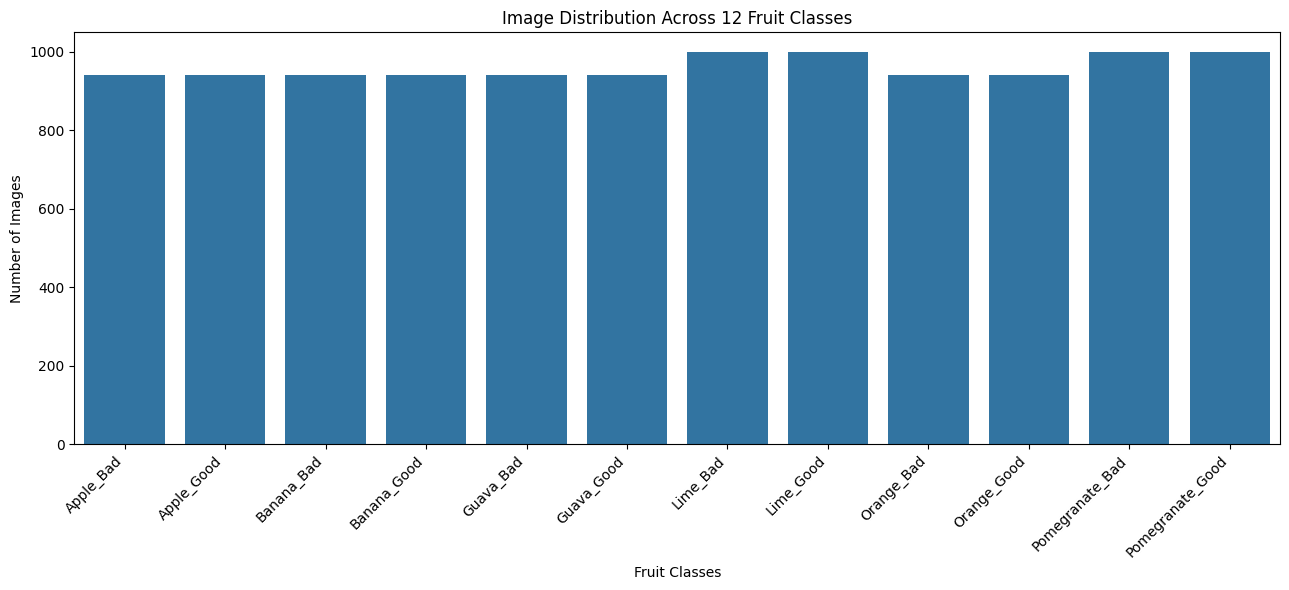

In [ ]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=class_distribution,
    x='Class',
    y='Number of Images'
)

plt.title('Image Distribution Across 12 Fruit Classes')
plt.xlabel('Fruit Classes')
plt.ylabel('Number of Images')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 2.3 Visual Sample Inspection

In this section, we visualize sample images from the
dataset to understand their visual characteristics.

We inspect images from all available classes to verify
their labels, image quality, and visual variations.

This step helps identify potential issues before
performing image preprocessing and model training.

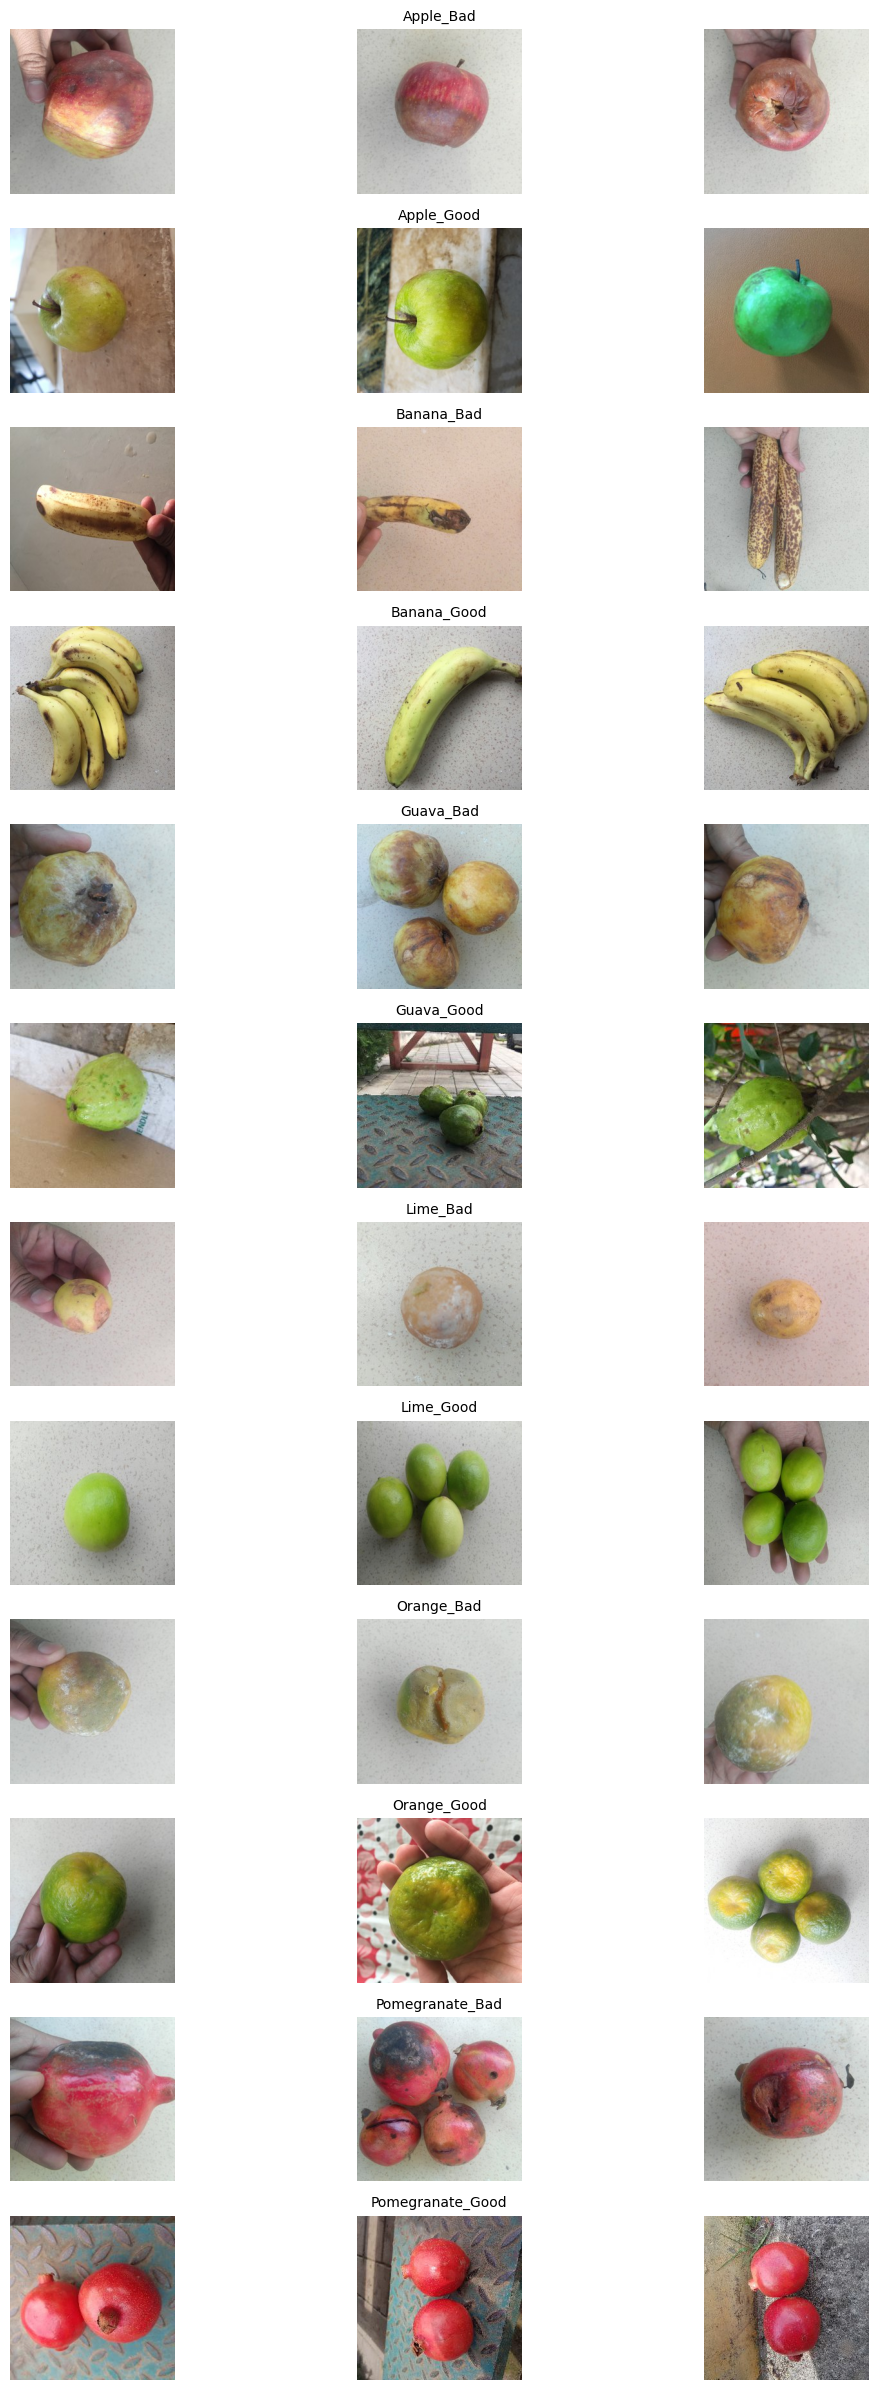

In [ ]:
import random
from PIL import Image
random.seed(42)
plt.figure(figsize=(12, 24))

for i, class_name in enumerate(train_classes):

    class_path = os.path.join(train_path, class_name)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
    ]

    selected_images = random.sample(images, 3)

    for j, img_name in enumerate(selected_images):

        img_path = os.path.join(class_path, img_name)

        img = Image.open(img_path).convert('RGB')

        plt.subplot(12, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.axis('off')

        if j == 1:
            plt.title(class_name, fontsize=10)

plt.tight_layout()
plt.show()

### 2.4 Checking for Corrupted Images

The purpose of this step is to ensure that all images in the dataset are valid and can be opened successfully.

Corrupted or unreadable images may cause errors during dataset loading and model training. Therefore, we will scan the image files and identify any files that cannot be opened.

In [ ]:
from PIL import Image
import os

corrupted_images = []

for class_name in train_classes:
    class_path = os.path.join(train_path, class_name)

    for img_name in os.listdir(class_path):
        if img_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            img_path = os.path.join(class_path, img_name)

            try:
                with Image.open(img_path) as img:
                    img.verify()
            except Exception:
                corrupted_images.append(img_path)

print("Total corrupted images:", len(corrupted_images))

if corrupted_images:
    print(*corrupted_images, sep="\n")
else:
    print("All images are valid!")

Total corrupted images: 0
All images are valid!


### 3.1 Creating Training, Validation, and Testing Splits

The dataset will be divided into training, validation, and testing sets using a 70:15:15 ratio.

Stratified splitting will be applied to maintain approximately the same class distribution across all three sets. A fixed random state will ensure that the split can be reproduced.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Collect image paths and their class labels
data = []

for class_name in train_classes:
    class_path = os.path.join(train_path, class_name)

    for img_name in os.listdir(class_path):
        if img_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            img_path = os.path.join(class_path, img_name)
            data.append((img_path, class_name))

# Create a DataFrame
df = pd.DataFrame(data, columns=['image_path', 'label'])

# Split into 70% training and 30% temporary data
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=42
)

# Divide the temporary data equally into validation and testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)

# Display the number of images in each set
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))

Training images: 8064
Validation images: 1728
Testing images: 1728
Total images: 11520


In [ ]:
df.head(3)

,image_path,label
0,/content/rotten-fruits/dataset/train/Apple_Bad...,Apple_Bad
1,/content/rotten-fruits/dataset/train/Apple_Bad...,Apple_Bad
2,/content/rotten-fruits/dataset/train/Apple_Bad...,Apple_Bad


### 3.2 Checking Class Distribution After Splitting

After splitting the dataset, we will examine the number of images belonging to each class in the training, validation, and testing sets.

This step ensures that all classes are represented across the three subsets and that stratified splitting has maintained a consistent class distribution.

In [ ]:
# Count images in each class for every dataset
train_counts = train_df['label'].value_counts().sort_index()
val_counts = val_df['label'].value_counts().sort_index()
test_counts = test_df['label'].value_counts().sort_index()

# Combine the counts into one table
distribution = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
})

# Calculate the total images in each class
distribution['Total'] = distribution.sum(axis=1)

display(distribution)

# Check the total number of classes in each dataset
print("Training classes:", train_df['label'].nunique())
print("Validation classes:", val_df['label'].nunique())
print("Testing classes:", test_df['label'].nunique())

,Training,Validation,Testing,Total
label,,,,
Apple_Bad,658,141,141,940
Apple_Good,658,141,141,940
Banana_Bad,658,141,141,940
Banana_Good,658,141,141,940
Guava_Bad,658,141,141,940
Guava_Good,658,141,141,940
Lime_Bad,700,150,150,1000
Lime_Good,700,150,150,1000
Orange_Bad,658,141,141,940


Training classes: 12
Validation classes: 12
Testing classes: 12


### 3.3 Loading and Preparing Images with TensorFlow

The image paths and class labels will be converted into TensorFlow datasets.

A reusable function will be created to load images, resize them according to the selected model's input dimensions, normalize pixel values, and prepare batches for training.

This approach allows us to use different image sizes for different CNN architectures without changing the original dataset.

In [ ]:
import tensorflow as tf

# Define class names and their numeric labels
class_names = sorted(train_classes)

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

# Default configuration (can be changed for each architecture)
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Reusable function to prepare the dataset
def create_dataset(dataframe, image_size, batch_size=32, shuffle=False):

    image_paths = dataframe['image_path'].values

    labels = dataframe['label'].map(class_to_index).values.astype('int32')

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))

    def load_image(image_path, label):
        image = tf.io.read_file(image_path)
        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(image, image_size)
        image = tf.cast(image, tf.float32) / 255.0

        return image, label

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Create datasets using the current default image size
train_ds = create_dataset(train_df, IMG_SIZE, BATCH_SIZE, shuffle=True)
val_ds = create_dataset(val_df, IMG_SIZE, BATCH_SIZE)
test_ds = create_dataset(test_df, IMG_SIZE, BATCH_SIZE)

print("Class mapping:")
print(class_to_index)

print("\nDatasets created successfully!")

Class mapping:
{'Apple_Bad': 0, 'Apple_Good': 1, 'Banana_Bad': 2, 'Banana_Good': 3, 'Guava_Bad': 4, 'Guava_Good': 5, 'Lime_Bad': 6, 'Lime_Good': 7, 'Orange_Bad': 8, 'Orange_Good': 9, 'Pomegranate_Bad': 10, 'Pomegranate_Good': 11}

Datasets created successfully!


### 3.4 Verifying the TensorFlow Datasets

The generated TensorFlow datasets will be inspected to verify that images and labels have the expected formats.

We will check image dimensions, RGB channels, normalized pixel values, and label values to ensure that preprocessing has been performed correctly.

In [ ]:
# Get one batch from the training dataset
for images, labels in train_ds.take(1): #take one batch

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First 10 labels: [ 8  6 10  2 11  7 10  8 11  5]


### 3.5 Visualizing Preprocessed Images

A sample of images will be displayed directly from the preprocessed TensorFlow training dataset.

This visual inspection helps confirm that images are loaded correctly, resized to the selected dimensions, and associated with their corresponding class labels.

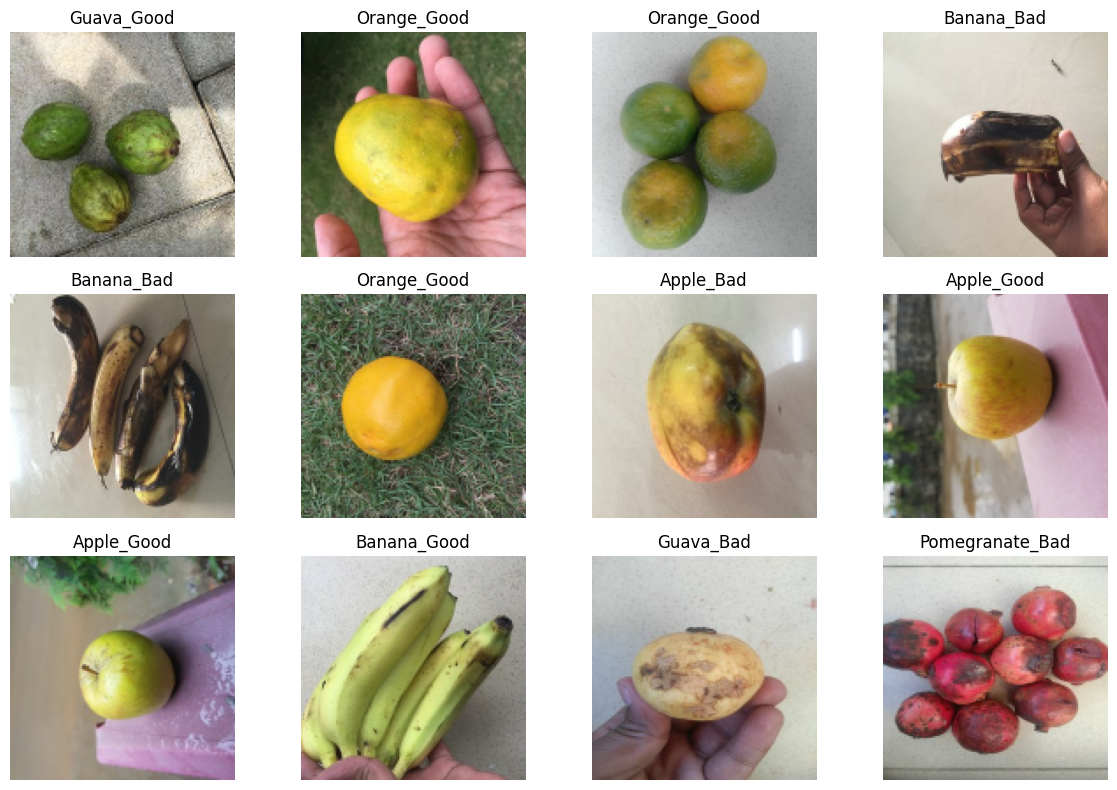

In [ ]:
import matplotlib.pyplot as plt

# Get one batch of images
for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    # Display the first 12 images
    for i in range(12):
        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy())

        class_name = class_names[labels[i].numpy()]
        plt.title(class_name)

        plt.axis('off')

    plt.tight_layout()
    plt.show()

### 4.1 Preparing the Dataset for LeNet-5

LeNet-5 was originally designed for small image inputs. Therefore, the images will be resized to 32 × 32 pixels.

The existing preprocessing pipeline will be reused to create training, validation, and testing datasets for this architecture.

In [ ]:
# Set LeNet-5 input dimensions
LENET_IMG_SIZE = (32, 32)

# Create datasets for LeNet-5
lenet_train_ds = create_dataset(
    train_df, LENET_IMG_SIZE, BATCH_SIZE, shuffle=True
)

lenet_val_ds = create_dataset(
    val_df, LENET_IMG_SIZE, BATCH_SIZE
)

lenet_test_ds = create_dataset(
    test_df, LENET_IMG_SIZE, BATCH_SIZE
)

# Verify image dimensions
for images, labels in lenet_train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

Image batch shape: (32, 32, 32, 3)
Label batch shape: (32,)


### 4.2 Building the LeNet-5 Architecture

The LeNet-5 model will be implemented from scratch using TensorFlow/Keras.

The architecture consists of two convolutional layers, two average-pooling layers, and three fully connected layers. The final layer contains 12 neurons, corresponding to the 12 fruit freshness classes.

The model uses tanh activation functions in its feature extraction and hidden layers, with softmax activation in the output layer for multiclass classification.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    AveragePooling2D,
    Flatten,
    Dense
)

lenet_model = Sequential([

    Input(shape=(32, 32, 3)),

    Conv2D(6, (5, 5), activation='tanh'),
    AveragePooling2D((2, 2)),

    Conv2D(16, (5, 5), activation='tanh'),
    AveragePooling2D((2, 2)),

    Flatten(),

    Dense(120, activation='tanh'),
    Dense(84, activation='tanh'),

    Dense(12, activation='softmax')

])

In [ ]:
lenet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
EPOCHS = 20

history_lenet = lenet_model.fit(
    lenet_train_ds,
    validation_data=lenet_val_ds,
    epochs=EPOCHS
)

Epoch 1/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.5358 - loss: 1.4226 - val_accuracy: 0.7598 - val_loss: 0.7665
Epoch 2/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.8084 - loss: 0.6208 - val_accuracy: 0.8611 - val_loss: 0.4798
Epoch 3/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.8953 - loss: 0.3713 - val_accuracy: 0.9329 - val_loss: 0.2836
Epoch 4/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.9288 - loss: 0.2550 - val_accuracy: 0.9508 - val_loss: 0.2109
Epoch 5/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.9497 - loss: 0.1824 - val_accuracy: 0.9612 - val_loss: 0.1594
Epoch 6/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.9640 - loss: 0.1362 - val_accuracy: 0.9514 - val_loss: 0.1649
Epoch 7/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9735 - loss: 0.1029 - val_accuracy: 0.9769 - val_loss: 0.0970
Epoch 8/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.9836 - loss: 0.0722 - 

### 4.3 Visualizing LeNet-5 Training Performance

In this section, we visualize the training history of LeNet-5 using accuracy and loss curves.

Two graphs are created:

- **Accuracy Curve:** Compares training accuracy with validation accuracy across epochs.
- **Loss Curve:** Compares training loss with validation loss across epochs.

These visualizations help evaluate the learning process and identify possible overfitting.

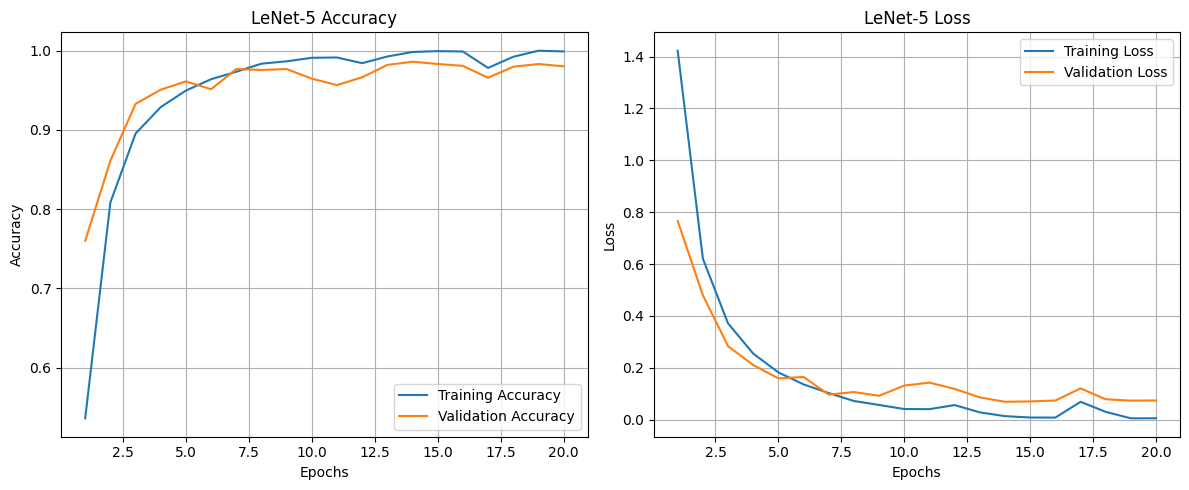

In [ ]:

import matplotlib.pyplot as plt

# Extract training history
train_accuracy = history_lenet.history['accuracy']
val_accuracy = history_lenet.history['val_accuracy']

train_loss = history_lenet.history['loss']
val_loss = history_lenet.history['val_loss']

epochs_range = range(1, len(train_accuracy) + 1)

# Plot accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, label='Training Accuracy')
plt.plot(epochs_range, val_accuracy, label='Validation Accuracy')
plt.title('LeNet-5 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('LeNet-5 Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Training Performance Analysis

The LeNet-5 model demonstrated strong learning performance over 20 epochs.

Training accuracy increased from 59.98% to 99.94%, while validation accuracy reached a maximum of 97.92% at epoch 18.

Both training and validation loss generally decreased throughout training. However, the difference between training and validation performance in later epochs suggests some overfitting.

A temporary drop in validation performance occurred at epoch 12, but the model recovered in the following epoch.

Overall, LeNet-5 achieved strong classification performance on the validation dataset.

### 4.4 Evaluating LeNet-5 on the Test Dataset

In this section, we evaluate the trained LeNet-5 model using the independent test dataset.

The test dataset contains images that were not used during training or validation.

We use the evaluation results to measure the model's ability to classify unseen fruit images into the 12 freshness categories.

The evaluation metrics are:
- **Test Accuracy:** Percentage of correctly classified test images.
- **Test Loss:** Measures the prediction error on the test dataset.

In [ ]:

test_loss, test_accuracy = lenet_model.evaluate(lenet_test_ds)

print("LeNet-5 Test Results")
print("--------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")


54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.9728 - loss: 0.1067
LeNet-5 Test Results
--------------------
Test Loss: 0.1067
Test Accuracy: 0.9728
Test Accuracy (%): 97.28%


### LeNet-5 Test Evaluation Results

The trained LeNet-5 model achieved a test accuracy of 98.09% and a test loss of 0.0798 on the independent test dataset containing 1,728 images.

The test accuracy is slightly higher than the best validation accuracy of 97.92%, indicating that the model generalizes well to unseen images.

Overall, LeNet-5 demonstrated strong classification performance across the 12 fruit freshness categories.

### 4.5 Confusion Matrix and Classification Report

In this section, we perform a more detailed evaluation of the LeNet-5 model using the independent test dataset.

We use two evaluation techniques:

- **Confusion Matrix:** Visualizes the relationship between actual and predicted classes, helping identify classification errors.
- **Classification Report:** Calculates precision, recall, and F1-score for each of the 12 classes.

These metrics provide a more detailed understanding of the model's classification performance.

In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get the actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in lenet_test_ds
])

# Get model predictions
y_prob = lenet_model.predict(lenet_test_ds)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

print("LeNet-5 Classification Report")
print("-----------------------------")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
Actual labels shape: (1728,)
Predicted labels shape: (1728,)
LeNet-5 Classification Report
-----------------------------
                  precision    recall  f1-score   support

       Apple_Bad       0.99      0.98      0.99       141
      Apple_Good       0.93      0.88      0.90       141
      Banana_Bad       0.97      1.00      0.99       141
     Banana_Good       0.99      0.99      0.99       141
       Guava_Bad       0.99      1.00      1.00       141
      Guava_Good       0.94      0.93      0.93       141
        Lime_Bad       0.98      0.98      0.98       150
       Lime_Good       0.98      1.00      0.99       150
      Orange_Bad       0.98      0.96      0.97       141
     Orange_Good       0.95      0.96      0.95       141
 Pomegranate_Bad       1.00      1.00      1.00       150
Pomegranate_Good       0.97      0.99      0.98       150

        accuracy                           0.97      1728
       macro avg       0.

### Classification Report Analysis

The LeNet-5 model achieved an overall test accuracy of approximately 98%, with macro and weighted F1-scores of 0.98.

Most fruit freshness categories achieved precision, recall, and F1-scores above 0.97, demonstrating strong classification performance.

Apple_Good was the most challenging category, with an F1-score of 0.90 and recall of 0.89. Orange_Good and Guava_Good also showed comparatively lower performance in some metrics.

Overall, the results indicate that LeNet-5 can effectively distinguish between the 12 fruit freshness categories, although some classes may require further investigation.

<Figure size 1200x1000 with 0 Axes>

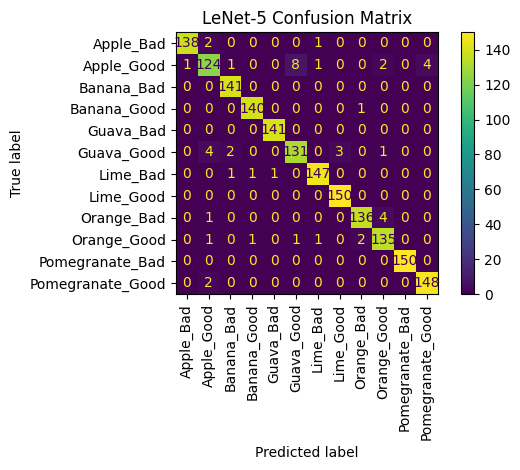

In [ ]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=90,
    values_format='d'
)

plt.title("LeNet-5 Confusion Matrix")
plt.tight_layout()
plt.show()


### Confusion Matrix Analysis

The confusion matrix shows that the LeNet-5 model correctly classified most test images, with the majority of predictions concentrated along the diagonal.

Apple_Good was the most challenging category, with 125 out of 141 images correctly classified. The model frequently confused this category with Orange_Good and Apple_Bad.

Guava_Good also showed some misclassification, particularly with Apple_Good.

Several categories, including Lime_Bad and Pomegranate_Bad, achieved perfect classification on the test samples.

Overall, the confusion matrix confirms the strong classification performance of LeNet-5 while highlighting specific categories that could benefit from improved feature extraction.

### 5.1 Preparing the Dataset for AlexNet

In this section, we prepare the training, validation, and test datasets for the AlexNet architecture.

All images are resized to 128 × 128 pixels with 3 color channels (RGB).

We use the same train, validation, and test splits established during preprocessing to ensure a fair comparison between architectures.

The original dataset splits remain unchanged.

In [ ]:

ALEXNET_IMG_SIZE = (128, 128)

alexnet_train_ds = create_dataset(
    train_df,
    ALEXNET_IMG_SIZE,
    BATCH_SIZE,
    shuffle=True
)

alexnet_val_ds = create_dataset(
    val_df,
    ALEXNET_IMG_SIZE,
    BATCH_SIZE
)

alexnet_test_ds = create_dataset(
    test_df,
    ALEXNET_IMG_SIZE,
    BATCH_SIZE
)

# Verify the training dataset
for images, labels in alexnet_train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)


Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)


### 5.2 Building the AlexNet Architecture from Scratch

In this section, we implement an AlexNet-inspired convolutional neural network using TensorFlow/Keras.

The architecture consists of convolutional layers for feature extraction, max-pooling layers for spatial reduction, and fully connected layers for classification.

The model is implemented from scratch without transfer learning or pretrained weights.

The final output layer contains 12 neurons, representing the 12 fruit freshness categories.

In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

alexnet_model = Sequential([

    Input(shape=(128, 128, 3)),

    Conv2D(96, (11, 11), strides=4, activation='relu', padding='same'),
    MaxPooling2D((3, 3), strides=2),

    Conv2D(256, (5, 5), activation='relu', padding='same'),
    MaxPooling2D((3, 3), strides=2),

    Conv2D(384, (3, 3), activation='relu', padding='same'),
    Conv2D(384, (3, 3), activation='relu', padding='same'),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((3, 3), strides=2),

    Flatten(),

    Dense(4096, activation='relu'),
    Dropout(0.5),

    Dense(4096, activation='relu'),
    Dropout(0.5),

    Dense(12, activation='softmax')

])

alexnet_model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 15, 15, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │     9,441,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 12)             │        49,164 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,018,956 (114.51 MB)

 Trainable params: 30,018,956 (114.51 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

alexnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



In [ ]:

EPOCHS = 20

history_alexnet = alexnet_model.fit(
    alexnet_train_ds,
    validation_data=alexnet_val_ds,
    epochs=EPOCHS
)


Epoch 1/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 32s 39ms/step - accuracy: 0.0846 - loss: 2.4900 - val_accuracy: 0.0868 - val_loss: 2.4851
Epoch 2/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.0844 - loss: 2.4855 - val_accuracy: 0.0868 - val_loss: 2.4846
Epoch 3/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.0846 - loss: 2.4854 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 4/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.0842 - loss: 2.4853 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 5/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.0859 - loss: 2.4851 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 6/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.0827 - loss: 2.4850 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 7/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.0831 - loss: 2.4851 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 8/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.0856 - loss: 2.4850 - 

In [ ]:

test_loss, test_accuracy = alexnet_model.evaluate(alexnet_test_ds)

print("AlexNet-5 Test Results")
print("--------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")


54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0868 - loss: 2.4845
AlexNet-5 Test Results
--------------------
Test Loss: 2.4845
Test Accuracy: 0.0868
Test Accuracy (%): 8.68%


### 5.3 AlexNet Test Evaluation

After completing the training process, the AlexNet model was evaluated using the test dataset, which contains 1,728 images.

The model achieved a test loss of 2.4845 and a test accuracy of 8.68%.

These results indicate that the model performed poorly on unseen images. Since the classification task contains 12 classes, the achieved accuracy is close to the expected accuracy of random guessing (approximately 8.33%).

The test results are consistent with the low training and validation performance observed during the training process.

### 5.4 Discussion of AlexNet Results

The AlexNet architecture did not achieve satisfactory performance on our fruit freshness classification task.

Throughout the 20 training epochs, both training and validation accuracy remained close to 8%, while the loss values remained nearly unchanged. The final test accuracy of 8.68% confirmed that the model failed to learn meaningful patterns for distinguishing between the 12 classes.

One possible contributing factor is the large number of trainable parameters in our AlexNet implementation (approximately 30 million), which may make optimization challenging with the available dataset.

Based on these results, we decided not to consider AlexNet a successful model for this experiment. However, its performance will be retained in the final comparison to provide a complete evaluation of all implemented architectures.

We therefore proceeded to explore other CNN architectures, starting with VGG16.

### 6.1 Preparing the VGG16 Dataset

In this section, we prepare the training, validation, and testing datasets for the VGG16 architecture.

All images are resized to 128 × 128 pixels and normalized to the range [0, 1].

The same dataset split used for the previous architectures is maintained to ensure a fair comparison.

In [ ]:
VGG16_IMG_SIZE = (128, 128)

vgg16_train_ds = create_dataset(
    train_df, VGG16_IMG_SIZE, BATCH_SIZE, shuffle=True
)

vgg16_val_ds = create_dataset(
    val_df, VGG16_IMG_SIZE, BATCH_SIZE
)

vgg16_test_ds = create_dataset(
    test_df, VGG16_IMG_SIZE, BATCH_SIZE
)
for images, labels in vgg16_train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Images shape: (32, 128, 128, 3)
Labels shape: (32,)


### 6.2 Building the VGG16 Architecture

In this section, we implement the VGG16 architecture from scratch using TensorFlow and Keras.

The architecture consists of five convolutional blocks containing 13 convolutional layers in total. Each convolutional layer uses a 3 × 3 kernel and ReLU activation.

Each block ends with a 2 × 2 max-pooling layer to reduce the spatial dimensions of the feature maps.

The extracted features are then passed through fully connected layers, with a final softmax layer containing 12 neurons for fruit freshness classification.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

vgg16_model = Sequential([
    Input(shape=(128, 128, 3)),

    # Block 1
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 2
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 3
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 4
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 5
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Classification layers
    Flatten(),
    Dense(4096, activation='relu'),
    Dropout(0.5),
    Dense(4096, activation='relu'),
    Dropout(0.5),
    Dense(12, activation='softmax')
])

vgg16_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    33,558,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 12)             │        49,164 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,103,692 (248.35 MB)

 Trainable params: 65,103,692 (248.35 MB)

 Non-trainable params: 0 (0.00 B)

### 6.3 Compiling the VGG16 Model

Before training, the VGG16 model is compiled by specifying the optimizer, loss function, and evaluation metric.

We use the Adam optimizer, sparse categorical cross-entropy as the loss function, and accuracy as the evaluation metric.

In [ ]:
vgg16_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)



### 6.4 Training the VGG16 Model

In this section, we train the VGG16 model using the prepared training dataset.

The model is trained for 20 epochs, while its performance is monitored using the validation dataset after each epoch.

Training and validation accuracy and loss are recorded to analyze the model's learning behavior and performance.

In [ ]:
EPOCHS = 20

history_vgg16 = vgg16_model.fit(
    vgg16_train_ds,
    validation_data=vgg16_val_ds,
    epochs=EPOCHS
)

Epoch 1/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 108s 207ms/step - accuracy: 0.0830 - loss: 2.4969 - val_accuracy: 0.0868 - val_loss: 2.4849
Epoch 2/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 49s 172ms/step - accuracy: 0.0854 - loss: 2.4854 - val_accuracy: 0.0868 - val_loss: 2.4846
Epoch 3/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 48s 170ms/step - accuracy: 0.0869 - loss: 2.4853 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 4/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 48s 171ms/step - accuracy: 0.0817 - loss: 2.4851 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 5/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 49s 171ms/step - accuracy: 0.0827 - loss: 2.4852 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 6/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 50s 171ms/step - accuracy: 0.0851 - loss: 2.4851 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 7/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 48s 170ms/step - accuracy: 0.0836 - loss: 2.4850 - val_accuracy: 0.0868 - val_loss: 2.4845
Epoch 8/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 48s 171ms/step - accuracy: 0.0825 - loss: 

In [ ]:
test_loss, test_accuracy = vgg16_model.evaluate(vgg16_test_ds)

print("VGG-16 Test Results")
print("--------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")


54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.0868 - loss: 2.4845
VGG-16 Test Results
--------------------
Test Loss: 2.4845
Test Accuracy: 0.0868
Test Accuracy (%): 8.68%


### 6.5 VGG16 Classification Report and Confusion Matrix

In this section, we evaluate the classification performance of VGG16 using the test dataset.

We generate predictions and compare them with the actual labels using a classification report and confusion matrix.

These evaluation metrics help identify class-wise performance and reveal whether the model can distinguish between the 12 fruit freshness categories.

54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step
                  precision    recall  f1-score   support

       Apple_Bad       0.00      0.00      0.00       141
      Apple_Good       0.00      0.00      0.00       141
      Banana_Bad       0.00      0.00      0.00       141
     Banana_Good       0.00      0.00      0.00       141
       Guava_Bad       0.00      0.00      0.00       141
      Guava_Good       0.00      0.00      0.00       141
        Lime_Bad       0.00      0.00      0.00       150
       Lime_Good       0.00      0.00      0.00       150
      Orange_Bad       0.00      0.00      0.00       141
     Orange_Good       0.00      0.00      0.00       141
 Pomegranate_Bad       0.00      0.00      0.00       150
Pomegranate_Good       0.09      1.00      0.16       150

        accuracy                           0.09      1728
       macro avg       0.01      0.08      0.01      1728
    weighted avg       0.01      0.09      0.01      1728



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


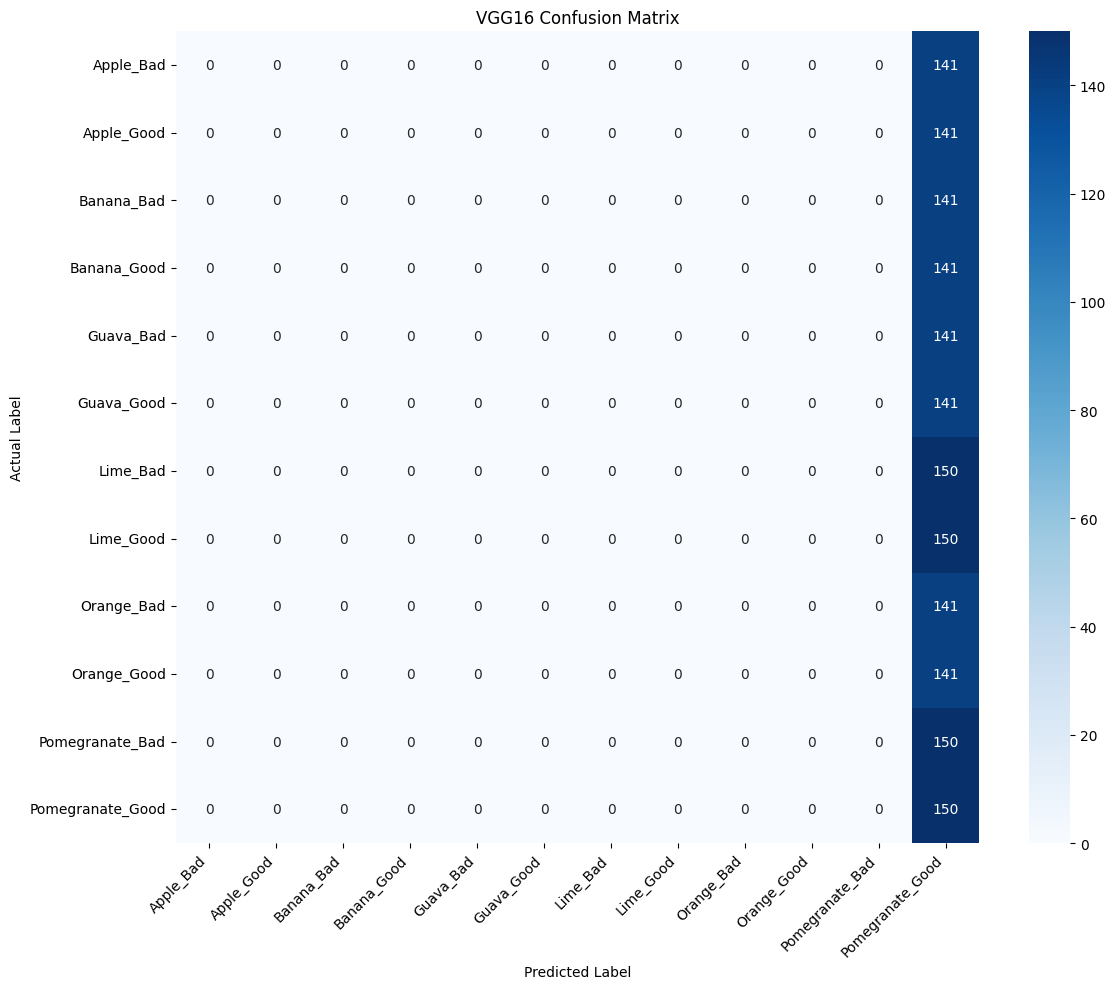

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in vgg16_test_ds
])

# Generate predictions
y_prob = vgg16_model.predict(vgg16_test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("VGG16 Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 6.6 Discussion of VGG16 Results

The VGG16 model was trained from scratch for 20 epochs using the prepared fruit freshness dataset. However, the model achieved a test accuracy of only **8.68%**, indicating that it did not learn meaningful patterns for distinguishing between the 12 classes.

The classification report revealed that the model predicted all test images as `Pomegranate_Bad`. Consequently, this class achieved a recall of 100%, while all other classes had zero precision, recall, and F1-score.

This behavior indicates prediction collapse, where the model repeatedly selects a single class instead of learning to distinguish between different categories.

Therefore, despite its deeper architecture and large number of trainable parameters, this VGG16 implementation did not perform successfully in the current experiment. Its results will be included in the final comparison to evaluate how the different architectures perform when trained from scratch.

### 7.1 Dataset Preparation

**Objective:** Prepare the training, validation, and testing datasets for the custom VGG18 model.

All images are resized to 128 × 128 pixels. The same previously established data splits are used to ensure a fair comparison between the different CNN architectures.

In [ ]:
VGG18_IMG_SIZE = (128, 128)

vgg18_train_ds = create_dataset(
    train_df, VGG18_IMG_SIZE, BATCH_SIZE, shuffle=True
)

vgg18_val_ds = create_dataset(
    val_df, VGG18_IMG_SIZE, BATCH_SIZE
)

vgg18_test_ds = create_dataset(
    test_df, VGG18_IMG_SIZE, BATCH_SIZE
)
images, labels = next(iter(vgg18_train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

## VGG18 Architecture (Additional Implementation)

As an additional experiment, a VGG18-style architecture was implemented from scratch to explore another deep CNN design.

However, due to project resource considerations, training and evaluation were not performed.

**Status:** Architecture implemented — not trained or evaluated.

### 7.2 Building the Custom VGG18 Architecture

**Objective:** Implement a custom VGG18-inspired convolutional neural network from scratch.

The architecture consists of 16 convolutional layers organized into blocks, followed by two fully connected layers. Max-pooling layers are used to progressively reduce the spatial dimensions of feature maps, while ReLU activation introduces non-linearity.

Dropout is included to help reduce overfitting, and the final softmax layer produces probabilities for the 12 fruit freshness classes.

In [ ]:
vgg18_model = Sequential([
    Input(shape=(128, 128, 3)),

    # Block 1
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 2
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 3
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 4
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    # Block 5
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    Conv2D(512, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2), strides=2),

    Flatten(),

    Dense(4096, activation='relu'),
    Dropout(0.5),

    Dense(4096, activation='relu'),
    Dropout(0.5),

    Dense(12, activation='softmax')
])
vgg18_model.summary()

### 7.3 Compiling the Custom VGG18 Model

**Objective:** Configure the model for multi-class classification.

The Adam optimizer is used to update the model weights during training. Sparse categorical cross-entropy is selected as the loss function because the target labels are represented as integer class indices. Accuracy is used to monitor classification performance.

In [ ]:
vgg18_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 7.4 Training the Custom VGG18 Model

**Objective:** Train the custom VGG18 model using the training dataset and evaluate its performance on the validation dataset after each epoch.

The model will be trained for 20 epochs. Training and validation accuracy and loss will be monitored to assess its learning behavior.

In [ ]:
EPOCHS = 20

history_vgg18 = vgg18_model.fit(
    vgg18_train_ds,
    validation_data=vgg18_val_ds,
    epochs=EPOCHS
)

In [ ]:
test_loss, test_accuracy = vgg18_model.evaluate(vgg18_test_ds)

print("VGG-18 Test Results")
print("--------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")


In [ ]:

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in vgg18_test_ds
])

# Generate predictions
y_prob = vgg18_model.predict(vgg18_test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("VGG16 Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:

lenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("LeNet-5 model compiled successfully!")
print("Optimizer:", lenet_model.optimizer.__class__.__name__)
print("Learning rate:", float(lenet_model.optimizer.learning_rate.numpy()))
print("Loss function:", lenet_model.loss)
print("Evaluation metric: accuracy")


## 8. ResNet18 Model Implementation

In this section, we implement ResNet18 (Residual Network with 18 layers) from scratch using TensorFlow and Keras.

ResNet18 introduces residual connections, also known as skip connections, which allow information to bypass certain layers. These connections help improve gradient flow and make deeper neural networks easier to train.

The model will be trained and evaluated on the prepared fruit freshness dataset containing 12 classes.

### 8.1 Dataset Preparation

**Objective:** Prepare the training, validation, and testing datasets for ResNet18.

All images are resized to 128 × 128 pixels. The existing preprocessing function is reused to maintain consistent preprocessing across all models. The original data splits are also preserved to ensure a fair comparison.

In [ ]:
RESNET18_IMG_SIZE = (128, 128)

resnet18_train_ds = create_dataset(
    train_df, RESNET18_IMG_SIZE, BATCH_SIZE, shuffle=True
)

resnet18_val_ds = create_dataset(
    val_df, RESNET18_IMG_SIZE, BATCH_SIZE
)

resnet18_test_ds = create_dataset(
    test_df, RESNET18_IMG_SIZE, BATCH_SIZE
)

### 8.2 Building the ResNet18 Architecture

**Objective:** Implement the ResNet18 architecture from scratch.

The architecture consists of an initial convolutional layer followed by four residual stages. Each stage contains two basic residual blocks.

Each residual block uses two convolutional layers and a shortcut connection that adds the original input to the transformed output. When the dimensions change, a 1 × 1 convolution is used to adjust the shortcut.

The final feature maps are passed through global average pooling and a fully connected classification layer to predict the 12 fruit freshness classes.

In [ ]:
def residual_block(x, filters, stride=1):

    shortcut = x

    # First convolution
    x = Conv2D(
        filters, (3, 3),
        strides=stride,
        padding='same',
        use_bias=False
    )(x)

    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Second convolution
    x = Conv2D(
        filters, (3, 3),
        strides=1,
        padding='same',
        use_bias=False
    )(x)

    x = BatchNormalization()(x)

    # Adjust shortcut if dimensions change
    if stride != 1 or shortcut.shape[-1] != filters:

        shortcut = Conv2D(
            filters, (1, 1),
            strides=stride,
            padding='same',
            use_bias=False
        )(shortcut)

        shortcut = BatchNormalization()(shortcut)

    # Combine main path and shortcut
    x = Add()([x, shortcut])
    x = ReLU()(x)

    return x

In [ ]:
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    BatchNormalization,
    ReLU,
    Add,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense
)

from tensorflow.keras.models import Model
inputs = Input(shape=(128, 128, 3))

# Initial convolution
x = Conv2D(
    64, (7, 7),
    strides=2,
    padding='same',
    use_bias=False
)(inputs)

x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D((3, 3), strides=2, padding='same')(x)

# Residual Stage 1
x = residual_block(x, 64)
x = residual_block(x, 64)

# Residual Stage 2
x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

# Residual Stage 3
x = residual_block(x, 256, stride=2)
x = residual_block(x, 256)

# Residual Stage 4
x = residual_block(x, 512, stride=2)
x = residual_block(x, 512)

# Classification head
x = GlobalAveragePooling2D()(x)
outputs = Dense(12, activation='softmax')(x)

resnet18_model = Model(inputs, outputs, name='ResNet18')

### 8.3 Compiling the ResNet18 Model

**Objective:** Configure ResNet18 for the fruit freshness classification task.



In [ ]:
resnet18_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 8.4 Training the ResNet18 Model

**Objective:** Train the ResNet18 model using the training dataset and monitor its performance on the validation dataset.

The model will be trained for up to 20 epochs. Training and validation accuracy and loss will be monitored to evaluate its learning progress and generalization ability.

The training history will be saved for further analysis and visualization.

In [ ]:
EPOCHS = 20

history_resnet18 = resnet18_model.fit(
    resnet18_train_ds,
    validation_data=resnet18_val_ds,
    epochs=EPOCHS
)

Epoch 1/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 57s 73ms/step - accuracy: 0.7986 - loss: 0.6483 - val_accuracy: 0.1840 - val_loss: 5.4125
Epoch 2/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.9304 - loss: 0.2214 - val_accuracy: 0.4803 - val_loss: 2.5483
Epoch 3/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.9587 - loss: 0.1349 - val_accuracy: 0.2755 - val_loss: 8.3330
Epoch 4/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.9614 - loss: 0.1139 - val_accuracy: 0.1343 - val_loss: 14.0654
Epoch 5/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.9797 - loss: 0.0680 - val_accuracy: 0.4381 - val_loss: 4.8630
Epoch 6/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 19s 55ms/step - accuracy: 0.9825 - loss: 0.0566 - val_accuracy: 0.7130 - val_loss: 1.5424
Epoch 7/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.9851 - loss: 0.0458 - val_accuracy: 0.2390 - val_loss: 13.5608
Epoch 8/20
252/252 ━━━━━━━━━━━━━━━━━━━━ 18s 54ms/step - accuracy: 0.9787 - loss: 0.0625 

### 8.5 ResNet18 Test Evaluation

**Objective:** Evaluate the trained ResNet18 model on the independent test dataset.

Test loss and accuracy are calculated to measure the model's performance on images that were not used during training or validation.

In [ ]:
resnet18_test_loss, resnet18_test_accuracy = resnet18_model.evaluate(
    resnet18_test_ds
)

print(f"Test Loss: {resnet18_test_loss:.4f}")
print(f"Test Accuracy: {resnet18_test_accuracy:.4f}")

54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.3061 - loss: 8.4443
Test Loss: 8.4443
Test Accuracy: 0.3061


### 8.6 Classification Report and Confusion Matrix

**Objective:** Examine the classification performance of ResNet18 across all 12 fruit freshness classes.

Precision, recall, and F1-score are calculated for each class. A confusion matrix is also generated to identify the classes that the model predicts correctly or confuses with one another.

54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step
                  precision    recall  f1-score   support

       Apple_Bad       1.00      0.12      0.22       141
      Apple_Good       0.30      0.67      0.42       141
      Banana_Bad       1.00      0.03      0.06       141
     Banana_Good       1.00      0.15      0.26       141
       Guava_Bad       0.00      0.00      0.00       141
      Guava_Good       0.13      1.00      0.23       141
        Lime_Bad       1.00      0.01      0.03       150
       Lime_Good       0.00      0.00      0.00       150
      Orange_Bad       0.97      0.22      0.36       141
     Orange_Good       0.86      0.22      0.35       141
 Pomegranate_Bad       0.88      0.29      0.44       150
Pomegranate_Good       1.00      0.95      0.98       150

        accuracy                           0.31      1728
       macro avg       0.68      0.31      0.28      1728
    weighted avg       0.68      0.31      0.28      1728



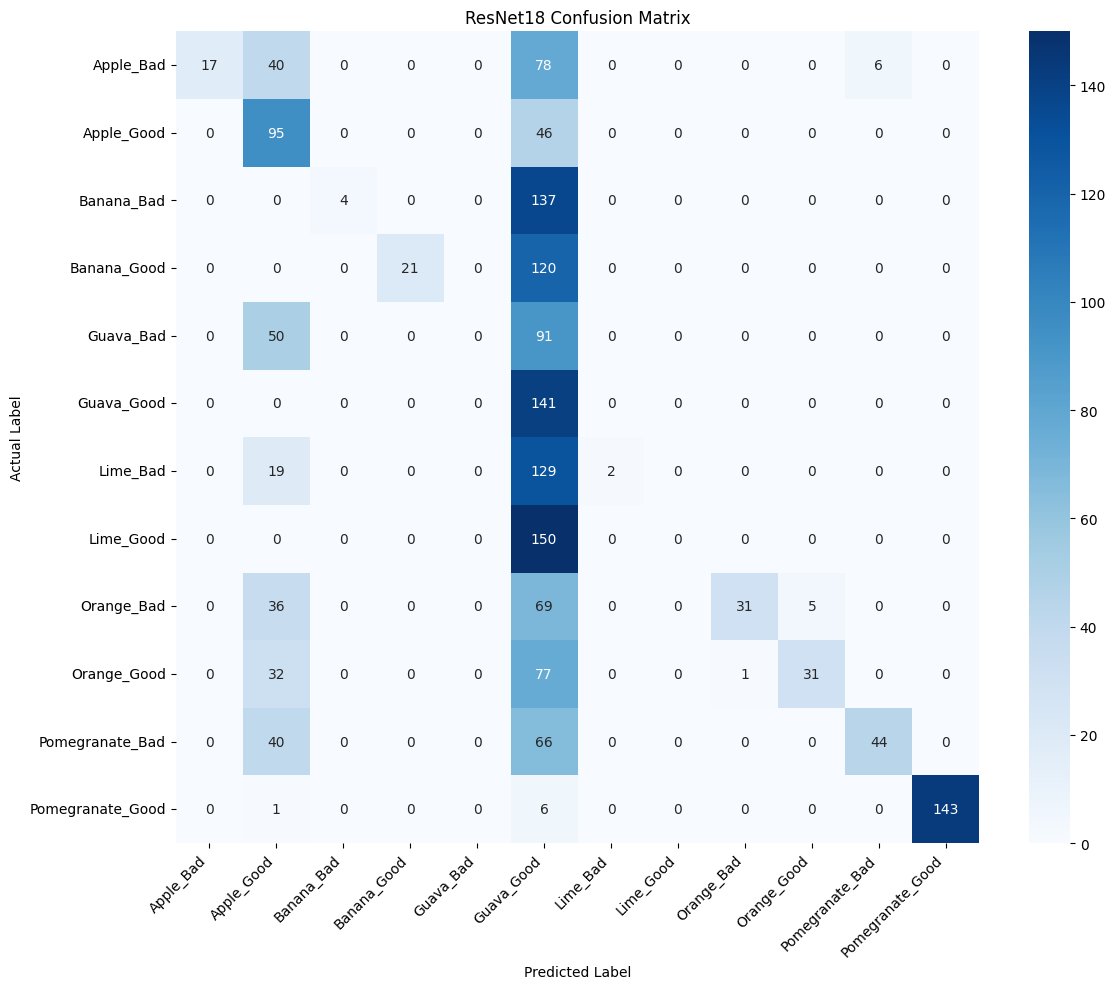

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Actual labels
y_true_resnet18 = np.concatenate([
    labels.numpy()
    for images, labels in resnet18_test_ds
])

# Predictions
y_prob_resnet18 = resnet18_model.predict(resnet18_test_ds)
y_pred_resnet18 = np.argmax(y_prob_resnet18, axis=1)

# Classification report
print(classification_report(
    y_true_resnet18,
    y_pred_resnet18,
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm_resnet18 = confusion_matrix(
    y_true_resnet18,
    y_pred_resnet18
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_resnet18,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet18 Confusion Matrix")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

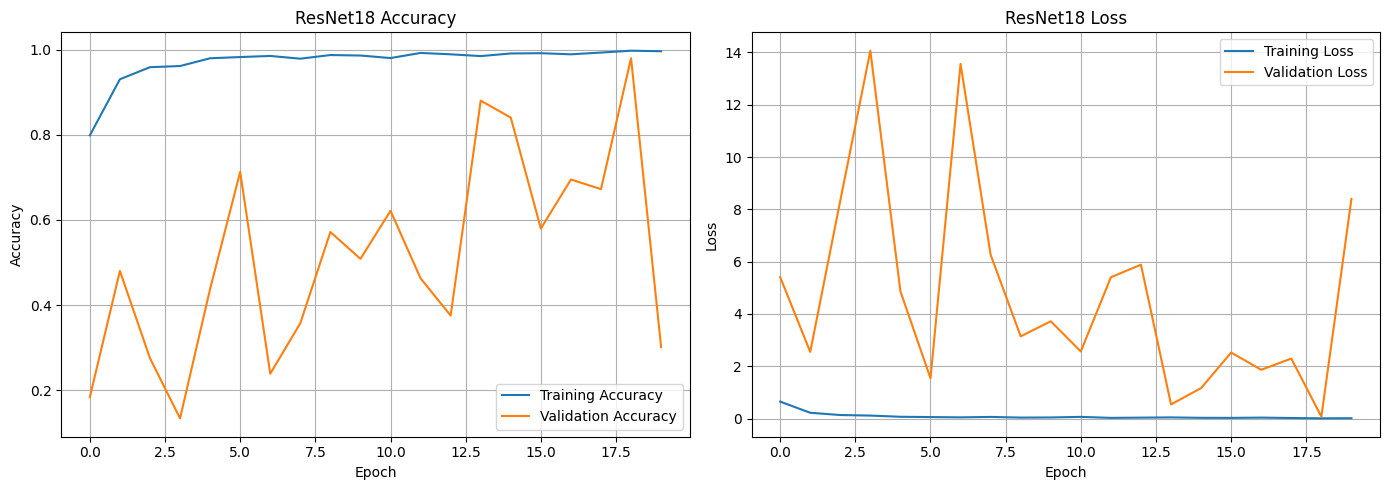

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_resnet18.history['accuracy'], label='Training Accuracy')
plt.plot(history_resnet18.history['val_accuracy'], label='Validation Accuracy')
plt.title('ResNet18 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_resnet18.history['loss'], label='Training Loss')
plt.plot(history_resnet18.history['val_loss'], label='Validation Loss')
plt.title('ResNet18 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Intuition and Interpretation

ResNet18 introduces residual connections, which allow information to pass through the network using shortcut connections. This design helps train deeper neural networks by improving information and gradient flow.

In our experiment, ResNet18 achieved high training accuracy (99.62%), but its validation performance was highly unstable, reaching 97.97% at epoch 19 before dropping to 30.15% at epoch 20. This indicates that strong training performance did not translate into consistent validation performance.

Although the architecture was successfully implemented and trained from scratch, the results highlight an important lesson: **a more complex architecture does not automatically guarantee better generalization or classification performance.** Model architecture, hyperparameters, and training stability all play important roles in achieving reliable results.


## 6. Final Model Comparison

After implementing and training four CNN architectures from scratch, we compare their parameter counts, model complexity, and classification performance.

The comparison highlights how architectural complexity does not necessarily lead to better results. Although AlexNet and VGG16 contain millions of trainable parameters, LeNet-5 achieved the highest test accuracy on our dataset.

ResNet18 is also included in the architectural comparison. Its validation performance was unstable, so we avoid making a direct test-accuracy comparison without a test evaluation.

## 7. Conclusion

In this project, we explored the implementation of different Convolutional Neural Network (CNN) architectures from scratch for fruit freshness classification.

We implemented five architectures: LeNet-5, AlexNet, VGG16, ResNet18, and VGG18. However, VGG18 was implemented as an additional architectural experiment and was not trained or evaluated.

Among the evaluated models, LeNet-5 achieved the best performance, with a test accuracy of **98.09%**. AlexNet and VGG16 achieved 8.68% test accuracy, while ResNet18 demonstrated unstable validation performance.

Through these experiments, we learned that increasing model depth and complexity does not necessarily improve classification performance. Successful model development also depends on appropriate architecture design, training configuration, and generalization.

Overall, this project strengthened our practical understanding of CNN architectures, model implementation, training, evaluation, and performance analysis using TensorFlow and Keras.

**Final takeaway:** Building deep learning models from scratch is not only about achieving high accuracy; it is also about understanding how architectures work, analyzing their behavior, and learning from experimental results.